In [1]:
import sys
import torch

print("Python environment:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda:0")

    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

    # Perform an actual computation on the GPU
    x = torch.randn(2048, 2048, device=device)
    y = x @ x

    torch.cuda.synchronize()

    print("Input tensor device:", x.device)
    print("Output tensor device:", y.device)
    print("GPU computation: SUCCESS")

    del x, y
    torch.cuda.empty_cache()

else:
    print("GPU unavailable — do not start training yet.")

Python environment: E:\Driver-Drowsiness\environment\python.exe
PyTorch version: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU
GPU memory: 4.0 GB
Input tensor device: cuda:0
Output tensor device: cuda:0
GPU computation: SUCCESS


In [2]:
import sys
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Select GPU whenever available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Training device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: E:\Driver-Drowsiness\environment\python.exe
PyTorch: 2.14.0+cu130
Training device: cuda:0
GPU: NVIDIA GeForce RTX 3050 4GB Laptop GPU


In [3]:
DATA_DIR = Path(r"E:\Driver-Drowsiness\data\raw")

def load_manifest(split):
    manifest_path = DATA_DIR / f"{split}.txt"

    records = []

    with open(manifest_path, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split()

            if not parts:
                continue

            image_path = DATA_DIR / parts[0].replace("\\", "/")
            label = int(parts[-1])

            if label not in (0, 1):
                raise ValueError(f"Unexpected label: {label}")

            records.append({
                "path": str(image_path),
                "label": label,
                "class": "Active" if label == 0 else "Fatigue"
            })

    df = pd.DataFrame(records)

    # Verify paths before training
    missing = sum(not Path(p).is_file() for p in df["path"])

    if missing:
        raise FileNotFoundError(
            f"{missing} image files are missing from the {split} split."
        )

    return df


train_df = load_manifest("train")
val_df = load_manifest("val")
test_df = load_manifest("test")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

Train: 6384
Validation: 1715
Test: 909
Total: 9008

Training class distribution:
class
Active     3192
Fatigue    3192
Name: count, dtype: int64


In [4]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps

IMAGE_SIZE = 224
BATCH_SIZE = 32

class Letterbox:
    def __init__(self, size, fill=(0, 0, 0)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.LANCZOS
        )

        canvas = Image.new(
            "RGB",
            (self.size, self.size),
            self.fill
        )

        x = (self.size - image.width) // 2
        y = (self.size - image.height) // 2
        canvas.paste(image, (x, y))

        return canvas


train_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms ready!")

Transforms ready!


In [5]:
class DrowsinessDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")

            if self.transform:
                image = self.transform(image)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label

In [6]:
train_dataset = DrowsinessDataset(train_df, train_transform)
val_dataset = DrowsinessDataset(val_df, eval_transform)
test_dataset = DrowsinessDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 200
Validation batches: 54
Test batches: 29


In [7]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image tensor device:", images.device)
print("Label examples:", labels[:10].tolist())

# Move a test batch to the GPU to verify placement
images_gpu = images.to(device)
labels_gpu = labels.to(device)

print("GPU image device:", images_gpu.device)
print("GPU label device:", labels_gpu.device)

del images_gpu, labels_gpu

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image tensor device: cpu
Label examples: [1, 0, 0, 0, 0, 1, 0, 1, 0, 0]
GPU image device: cuda:0
GPU label device: cuda:0


In [8]:
class DrowsinessCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


print("CNN architecture defined successfully!")

CNN architecture defined successfully!


In [9]:
# Reproducibility
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = DrowsinessCNN().to(device)

total_params = sum(
    parameter.numel() for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Model device:", next(model.parameters()).device)

DrowsinessCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNo

In [10]:
# Take a small batch to limit memory use
images, labels = next(iter(train_loader))

images = images[:4].to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Output device:", outputs.device)

assert outputs.shape == (4, 2)
assert outputs.device.type == "cuda"

print("CNN forward pass on GPU: SUCCESS")

Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 2])
Output device: cuda:0
CNN forward pass on GPU: SUCCESS


In [11]:
from pathlib import Path
import time
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Use a smaller batch size for 4 GB VRAM
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training batch size:", BATCH_SIZE)
print("Training device:", device)
print("Model device:", next(model.parameters()).device)

Training batch size: 16
Training device: cuda:0
Model device: cuda:0


In [12]:
# Two-class classification: Active = 0, Fatigue = 1
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Save checkpoints and results on E:
MODEL_DIR = Path(r"E:\Driver-Drowsiness\models\cnn_baseline")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_model.pt"
LAST_CHECKPOINT_PATH = MODEL_DIR / "last_checkpoint.pt"

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Best model will be saved at:", BEST_MODEL_PATH)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Best model will be saved at: E:\Driver-Drowsiness\models\cnn_baseline\best_model.pt


In [13]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

        progress.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy


@torch.inference_mode()
def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(
        loader, desc="Evaluating", leave=False
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions,
            pos_label=1, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions,
            pos_label=1, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions,
            pos_label=1, zero_division=0
        )
    }

print("Training and evaluation functions ready!")

Training and evaluation functions ready!


In [14]:
EPOCHS = 8
PATIENCE = 3

best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_metrics = evaluate_model(
        model, val_loader, criterion, device
    )

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision_fatigue": val_metrics["precision"],
        "val_recall_fatigue": val_metrics["recall"],
        "val_f1_fatigue": val_metrics["f1"],
        "seconds": epoch_time
    })

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f}"
    )
    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Accuracy: {val_metrics['accuracy']:.4f}"
    )
    print(
        f"Fatigue Precision: {val_metrics['precision']:.4f} | "
        f"Recall: {val_metrics['recall']:.4f} | "
        f"F1: {val_metrics['f1']:.4f}"
    )
    print(f"Epoch time: {epoch_time:.1f} seconds")

    # Save a checkpoint after every completed epoch
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": val_metrics["loss"],
        "history": history
    }

    torch.save(checkpoint, LAST_CHECKPOINT_PATH)

    # Save the best model based on validation loss
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0

        torch.save(checkpoint, BEST_MODEL_PATH)
        print("Best model checkpoint saved.")

    else:
        epochs_without_improvement += 1
        print(
            f"No validation-loss improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

total_training_time = time.time() - training_start

history_df = pd.DataFrame(history)
history_df.to_csv(
    MODEL_DIR / "training_history.csv",
    index=False
)

print(f"\nTraining finished in {total_training_time / 60:.2f} minutes.")
print("Best validation loss:", best_val_loss)
print("Best model:", BEST_MODEL_PATH)

Training:   0%|          | 0/399 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 1/8
Train Loss: 0.5654 | Train Accuracy: 0.7212
Val Loss: 0.7353 | Val Accuracy: 0.6315
Fatigue Precision: 0.5616 | Recall: 0.9701 | F1: 0.7114
Epoch time: 630.2 seconds
Best model checkpoint saved.


Training:   0%|          | 0/399 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/108 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 7/8
Train Loss: 0.4806 | Train Accuracy: 0.7553
Val Loss: 0.4327 | Val Accuracy: 0.7580
Fatigue Precision: 0.8288 | Recall: 0.6090 | F1: 0.7021
Epoch time: 437.4 seconds
Best model checkpoint saved.


Training:   0%|          | 0/399 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/108 [00:00<?, ?it/s]


Epoch 8/8
Train Loss: 0.4612 | Train Accuracy: 0.7664
Val Loss: 0.8256 | Val Accuracy: 0.6501
Fatigue Precision: 0.5732 | Recall: 0.9900 | F1: 0.7260
Epoch time: 469.4 seconds
No validation-loss improvement: 1/3

Training finished in 62.41 minutes.
Best validation loss: 0.43265336605098437
Best model: E:\Driver-Drowsiness\models\cnn_baseline\best_model.pt


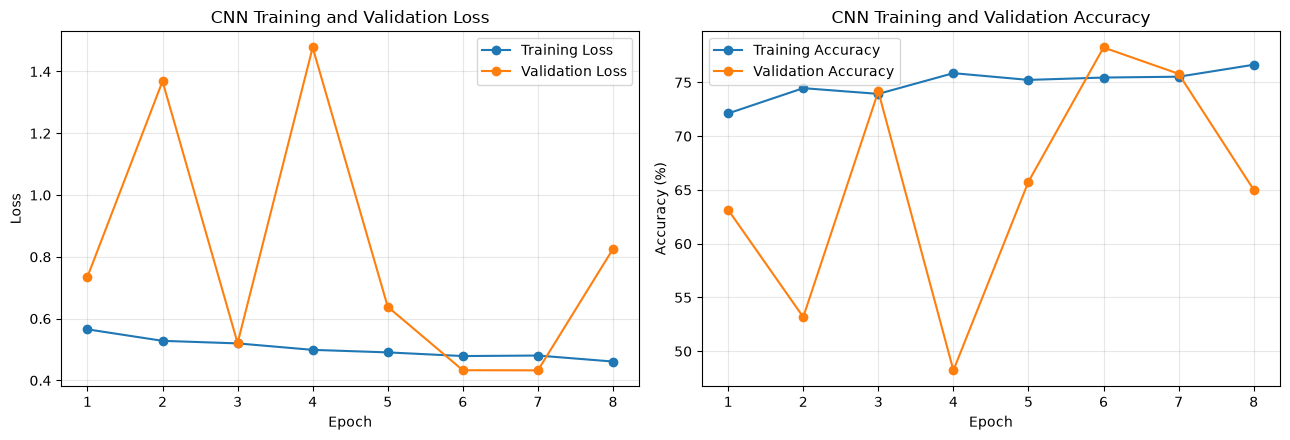

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Loss curves
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("CNN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(history_df["epoch"])
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curves
axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    marker="o",
    label="Training Accuracy"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)
axes[1].set_title("CNN Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_xticks(history_df["epoch"])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Loaded checkpoint from epoch: 7
Model device: cuda:0

Actual validation class counts:
Counter({0: 912, 1: 803})

Predicted validation class counts:
Counter({0: 1125, 1: 590})

Validation classification report:
              precision    recall  f1-score   support

      Active     0.7209    0.8893    0.7963       912
     Fatigue     0.8288    0.6090    0.7021       803

    accuracy                         0.7580      1715
   macro avg     0.7749    0.7491    0.7492      1715
weighted avg     0.7714    0.7580    0.7522      1715



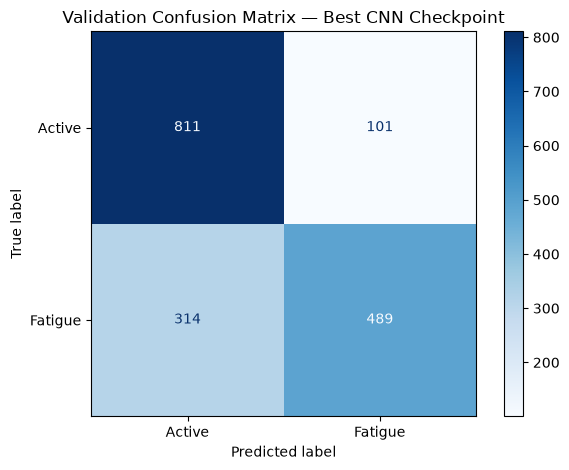

In [16]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from collections import Counter
import matplotlib.pyplot as plt
import torch

# Load the checkpoint selected by validation loss
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Model device:", next(model.parameters()).device)

# Collect validation predictions
all_predictions = []
all_true_labels = []
all_probabilities = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_true_labels.extend(labels.tolist())
        all_probabilities.extend(probabilities[:, 1].cpu().tolist())

print("\nActual validation class counts:")
print(Counter(all_true_labels))

print("\nPredicted validation class counts:")
print(Counter(all_predictions))

print("\nValidation classification report:")
print(
    classification_report(
        all_true_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["Active", "Fatigue"],
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Active", "Fatigue"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Validation Confusion Matrix — Best CNN Checkpoint")
plt.tight_layout()
plt.show()

In [18]:
import numpy as np
import pandas as pd
from IPython.display import display as show_table

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Convert validation labels and predicted Fatigue probabilities to arrays
true_labels = np.array(all_true_labels)
fatigue_probs = np.array(all_probabilities)

# Evaluate several decision thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    # Predict Fatigue (1) if its probability reaches the threshold
    predictions = (fatigue_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            true_labels, predictions
        ),
        "Fatigue Precision": precision_score(
            true_labels,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "Fatigue Recall": recall_score(
            true_labels,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "Fatigue F1": f1_score(
            true_labels,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "Predicted Fatigue": int(predictions.sum())
    })

# Create and display the results table
threshold_df = pd.DataFrame(threshold_results)

show_table(threshold_df.round(4))

,Threshold,Accuracy,Fatigue Precision,Fatigue Recall,Fatigue F1,Predicted Fatigue
0,0.30,0.7848,0.7188,0.8879,0.7944,992
1,0.35,0.8000,0.7578,0.8418,0.7976,892
2,0.40,0.7854,0.7750,0.7634,0.7691,791
3,0.45,0.7726,0.8077,0.6750,0.7354,671
4,0.50,0.7580,0.8288,0.6090,0.7021,590
5,0.55,0.7592,0.8625,0.5778,0.6920,538
6,0.60,0.7504,0.8850,0.5367,0.6682,487


Selected threshold: 0.35
Test accuracy:         0.7932
Fatigue precision:     0.7874
Fatigue recall:        0.8013
Fatigue F1-score:      0.7943

Test classification report:
              precision    recall  f1-score   support

      Active     0.7991    0.7851    0.7920       456
     Fatigue     0.7874    0.8013    0.7943       453

    accuracy                         0.7932       909
   macro avg     0.7933    0.7932    0.7932       909
weighted avg     0.7933    0.7932    0.7932       909



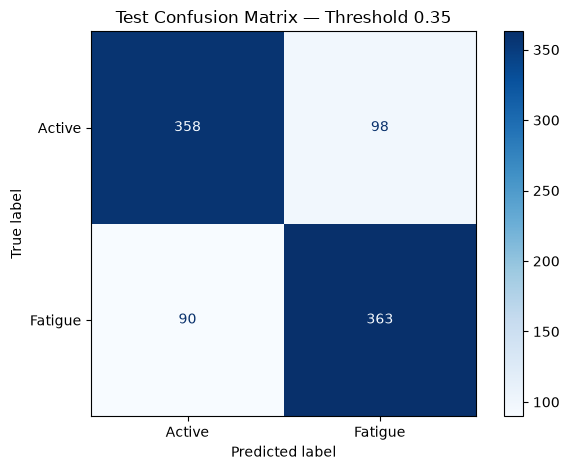

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Threshold chosen using validation results only
THRESHOLD = 0.35

model.eval()

test_true = []
test_fatigue_probs = []

# Run inference on the test set using the GPU
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        test_fatigue_probs.extend(
            probabilities[:, 1].cpu().numpy()
        )
        test_true.extend(labels.numpy())

test_true = np.array(test_true)
test_fatigue_probs = np.array(test_fatigue_probs)

# Apply the fixed threshold chosen on validation data
test_predictions = (
    test_fatigue_probs >= THRESHOLD
).astype(int)

# Calculate test metrics
test_accuracy = accuracy_score(test_true, test_predictions)

test_precision = precision_score(
    test_true, test_predictions,
    pos_label=1, zero_division=0
)

test_recall = recall_score(
    test_true, test_predictions,
    pos_label=1, zero_division=0
)

test_f1 = f1_score(
    test_true, test_predictions,
    pos_label=1, zero_division=0
)

print(f"Selected threshold: {THRESHOLD:.2f}")
print(f"Test accuracy:         {test_accuracy:.4f}")
print(f"Fatigue precision:     {test_precision:.4f}")
print(f"Fatigue recall:        {test_recall:.4f}")
print(f"Fatigue F1-score:      {test_f1:.4f}")

print("\nTest classification report:")
print(
    classification_report(
        test_true,
        test_predictions,
        labels=[0, 1],
        target_names=["Active", "Fatigue"],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm_test = confusion_matrix(
    test_true,
    test_predictions,
    labels=[0, 1]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Active", "Fatigue"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title(f"Test Confusion Matrix — Threshold {THRESHOLD:.2f}")
plt.tight_layout()
plt.show()